In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
import fit_lib as fit
import BM29_lib as BM29
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
plt.rcParams["text.usetex"] = False
from scipy import optimize
from scipy.optimize import curve_fit

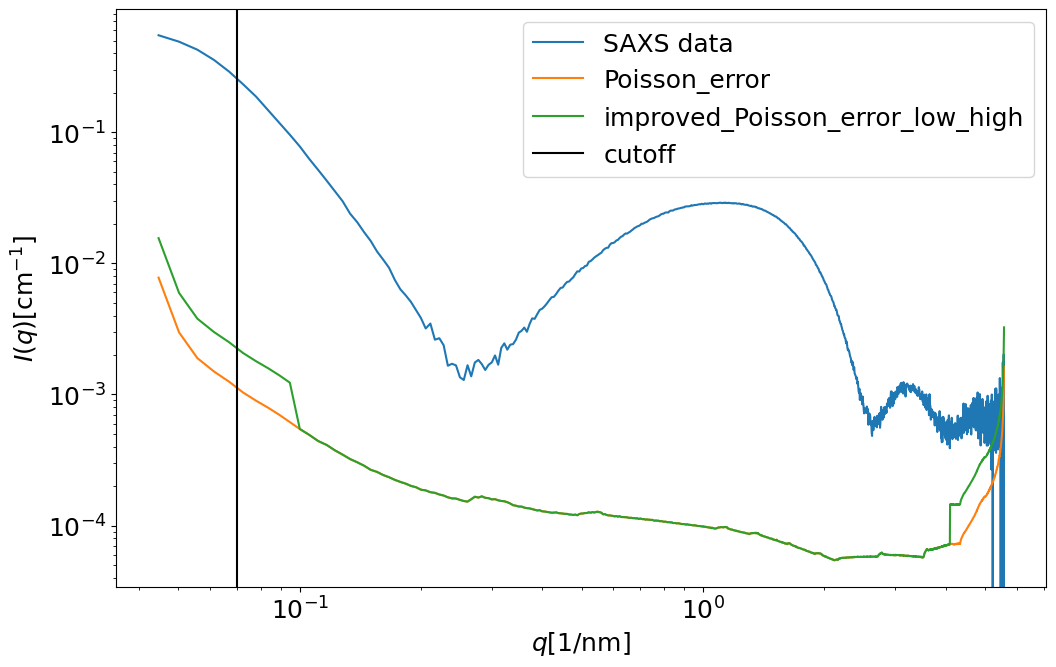

In [ ]:
# EXPLORE ERROR MODELS #############
sample = "BII_S9" # "BII_S9_15mM_LV4_PBS_FVII"
block = sample.split("_")[0]
block_path = BM29.blockpath(block)
dir_names = [x.name for x in block_path.iterdir()]
for dir_name in dir_names:
    if dir_name[:-13].endswith(sample):
        sub_dat_path = block_path / dir_name / "avg_and_sub" / BM29.sample_dict[sample]
        q, I, Ierr = np.loadtxt(sub_dat_path, unpack=True)

Ierr_op1 = BM29.improved_Poisson_error_low_high(q, Ierr)
Ierr_op2 = BM29.op_error_classic(q, I)
Ierr_op3 = BM29.op_error_focus_minimum_high(q, Ierr)
Ierr_op4 = BM29.op_error_focus_lowq_and_minimum(q, Ierr)

plt.figure(figsize=(12, 7.5))
plt.xlabel('$q [1/\\mathrm{nm}]$')
plt.ylabel('$I(q) [\\mathrm{cm}^{-1}]$')
plt.loglog(q, I, label="SAXS data")
plt.loglog(q, Ierr, label="Poisson_error")
plt.loglog(q, Ierr_op1, label="improved_Poisson_error_low_high")
# plt.loglog(q, Ierr_op2, label="op_error_classic")
# plt.loglog(q, Ierr_op3, label="op_error_focus_minimum_high")
# plt.loglog(q, Ierr_op4, label="op_error_focus_lowq_and_minimum")
plt.axvline(x = 0.07, c="black", label="cutoff")
plt.legend(loc="upper right")

In [ ]:
# EXPLORE ERROR MODELS #############
sample = "BII_S9" 
block = sample.split("_")[0]
block_path = BM29.blockpath(block)
dir_names = [x.name for x in block_path.iterdir()]
for dir_name in dir_names:
    if dir_name[:-13].endswith(sample):
        sub_dat_path = block_path / dir_name / "avg_and_sub" / BM29.sample_dict[sample]
        q, I, Ierr = np.loadtxt(sub_dat_path, unpack=True)

Ierr_op = BM29.improved_Poisson_error_low_high(q, Ierr)

p0_sph_asym    = []
p0_ellips_asym = []

fit_function_name = "ULV_spheric_asym_C4"
fit_function = lambda q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale, c4: fit.ULV_spheric_asym(q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale,      0, 0, c4)
residuals     = I - fit_function(q, *p0_sph_asym)
chi2_sph_asym = np.sum((residuals / Ierr_op)**2) / (len(I) - len(p0_sph_asym) - 1)

fit_function_name = "ellipsoid_asym_C4"
fit_function = lambda q,  R,  sigma_R,     eps, sigma_eps,  rho_h1, rho_h2,   sigma_h1, sigma_h2,  sigma_c,      z_h,    scale, c4: fit.ULV_ellipsoid_asym(q, R,  sigma_R,     eps, sigma_eps,  rho_h1, rho_h2,   sigma_h1, sigma_h2,  sigma_c,      z_h,    scale,   0, 0, c4)
residuals     = I - fit_function(q, *p0_ellips_asym)
chi2_ellips_asym = np.sum((residuals / Ierr_op)**2) / (len(I) - len(p0_ellips_asym) - 1)



